# Previsão de evasão de estudantes

Prova substitutiva da Fase 3 de Machine Learning Engineering.

O objetivo é treinar um modelo binário que diga se um aluno vai abandonar o curso, usando o perfil, a situação financeira e o desempenho nos dois primeiros semestres. Este notebook percorre as etapas na ordem em que foram feitas: qualidade dos dados, feature engineering, separação em treino e teste, validação cruzada, análise de overfitting e underfitting e avaliação final.

Todo o código reutilizável está no pacote `evasao/`. O notebook chama as mesmas funções que o script de treino (`python -m evasao.train`) e que o app em Streamlit.

In [1]:
import sys
import warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.metrics import classification_report, roc_curve
from sklearn.model_selection import learning_curve

from evasao import data, plots, schema, train
from evasao.features import AcademicFeatures
from evasao.model import build_pipeline, build_preprocessor, candidates

%matplotlib inline
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:.3f}".format)

## 1. A base

A planilha tem uma linha por aluno. São 27 variáveis explicativas e a coluna `Target`, com a situação do aluno ao final do período observado.

In [2]:
raw = data.load_raw()
raw.shape

(4424, 28)

In [3]:
raw.head()

,EstadoCivil,Curso,QualificacaoAnterior,QualificacaoAnteriorGrau,Nacionalidade,NotaAdmissao,NecessidadesEspeciais,Devedor,MensalidadesEmDia,Genero,Bolsista,International,UnidadesCurriculares1SemestreCreditado,UnidadesCurriculares1SemestreInscrito,UnidadesCurriculares1SemestreAvaliacoes,UnidadesCurriculares1SemestreAprovado,UnidadesCurriculares1SemestreGrau,UnidadesCurriculares1SemestreSemAvaliacoes,UnidadesCurriculares2SemestreCreditado,UnidadesCurriculares2SemestreInscrito,UnidadesCurriculares2SemestreAvaliacoes,UnidadesCurriculares2SemestreAprovado,UnidadesCurriculares2SemestreGrau,UnidadesCurriculares2SemestreSemAvaliacoes,TaxaDesemprego,TaxaInflacao,PIB,Target
0,Solteiro,Design de Animação e Multimédia,Ensino Secundário,122.000,Português,127.300,0,0,1,Masculino,0,0,0,0,0,0,0.000,0,0,0,0,0,0.000,0,10.800,1.400,1.740,Desistente
1,Solteiro,Turismo,Ensino Secundário,160.000,Português,142.500,0,0,0,Masculino,0,0,0,6,6,6,14.000,0,0,6,6,6,13666666666666600.000,0,13.900,-0.300,0.790,Graduado
2,Solteiro,Design de Comunicação,Ensino Secundário,122.000,Português,124.800,0,0,0,Masculino,0,0,0,6,0,0,0.000,0,0,6,0,0,0.000,0,10.800,1.400,1.740,Desistente
3,Solteiro,Jornalismo e Comunicação,Ensino Secundário,122.000,Português,119.600,0,0,1,Feminino,0,0,0,6,8,6,13428571428571400.000,0,0,6,10,5,12.400,0,9.400,-0.800,-3.120,Graduado
4,Casado,Serviço Social (prestação nocturna),Ensino Secundário,100.000,Português,141.500,0,0,1,Feminino,0,0,0,6,9,5,12333333333333300.000,0,0,6,6,6,13.000,0,13.900,-0.300,0.790,Graduado


In [4]:
pd.DataFrame({"tipo": raw.dtypes.astype(str), "nulos": raw.isna().sum(), "valores distintos": raw.nunique()})

,tipo,nulos,valores distintos
EstadoCivil,str,0,6
Curso,str,0,17
QualificacaoAnterior,str,0,16
QualificacaoAnteriorGrau,float64,0,101
Nacionalidade,str,0,21
NotaAdmissao,float64,0,620
NecessidadesEspeciais,int64,0,2
Devedor,int64,0,2
MensalidadesEmDia,int64,0,2
Genero,str,0,2


Não há valores nulos. As variáveis se dividem em três grupos:

- **categóricas** (texto): estado civil, curso, qualificação anterior, nacionalidade e gênero;
- **binárias** (0/1): necessidades especiais, devedor, mensalidades em dia, bolsista e aluno internacional;
- **numéricas**: notas de entrada, contadores de unidades curriculares por semestre e três indicadores econômicos.

## 2. Qualidade dos dados

### 2.1 Notas sem o separador decimal

As duas colunas de nota média por semestre deveriam estar na escala de 0 a 20. O resumo abaixo mostra que não estão: o máximo passa de 10¹⁶.

In [5]:
raw[schema.GRADE_COLUMNS].describe().T

,count,mean,std,min,25%,50%,75%,max
UnidadesCurriculares1SemestreGrau,4424.000,4458090894459428.000,6172473266574616.000,0.000,11.250,13.500,12166666666666600.000,17333333333333300.000
UnidadesCurriculares2SemestreGrau,4424.000,3928633958049681.000,5970123956711803.000,0.000,11.000,13.000,11666666666666600.000,18571428571428500.000


In [6]:
grade_column = schema.GRADE_COLUMNS[0]
raw.loc[raw[grade_column] > 0, grade_column].sample(8, random_state=7).to_frame()

,UnidadesCurriculares1SemestreGrau
3234,13.780
1717,10.000
884,12599999999999900.000
418,11.600
3658,12.400
1044,11.600
1616,13.750
455,11166666666666600.000


Os valores quebrados são a nota original sem a vírgula: `13,875` virou `13875` e `13,666...` virou `1,36e16`. Como toda nota válida fica entre 0 e 20, basta dividir cada valor acima de 20 pela potência de 10 que o traz de volta para a escala.

Três verificações confirmam o reparo:

1. depois dele, nenhuma nota passa de 20;
2. a nota é 0 exatamente nos alunos sem nenhuma unidade aprovada no semestre;
3. a menor nota diferente de zero fica perto de 10, que é a nota mínima de aprovação nessa escala.

In [7]:
frame = data.clean(raw)

checks = []
for semester in schema.SEMESTERS:
    grade = frame[schema.semester_column(semester, "Grau")]
    approved = frame[schema.semester_column(semester, "Aprovado")]
    checks.append(
        {
            "semestre": semester,
            "linhas reparadas": int((raw[schema.semester_column(semester, "Grau")] > 20).sum()),
            "nota máxima": grade.max(),
            "menor nota acima de zero": grade[grade > 0].min(),
            "nota zero = sem aprovação": bool(((grade == 0) == (approved == 0)).all()),
        }
    )
pd.DataFrame(checks)

,semestre,linhas reparadas,nota máxima,menor nota acima de zero,nota zero = sem aprovação
0,1,1790,18.875,9.800,True
1,2,1675,18.571,10.000,True


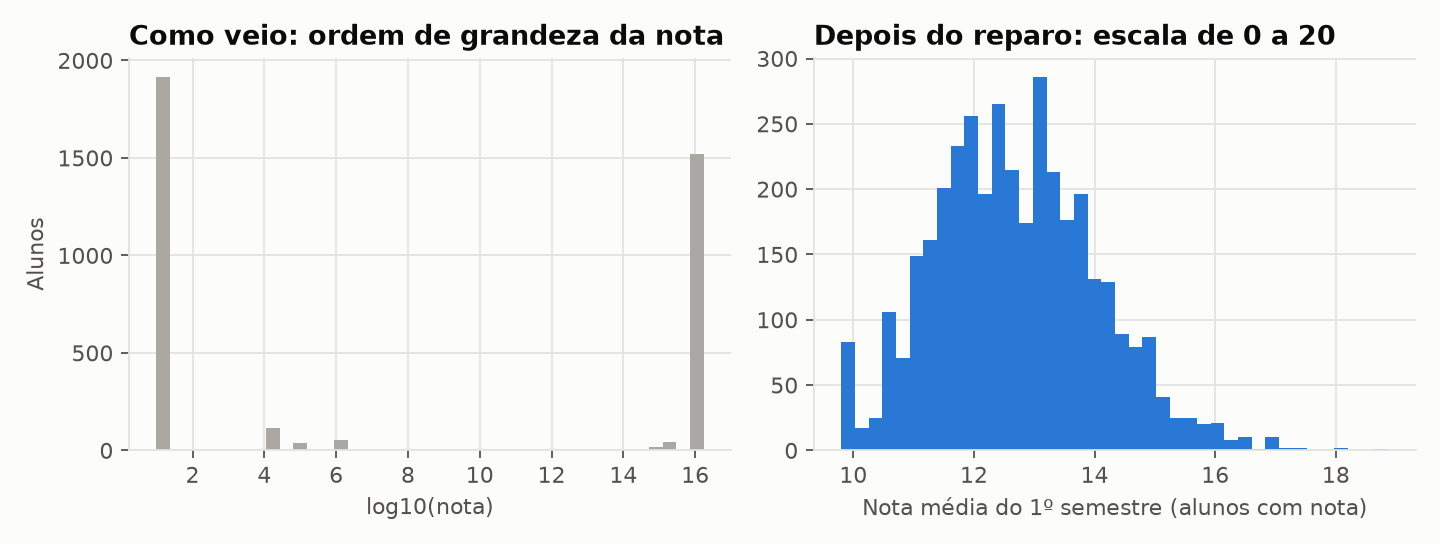

In [8]:
display(Image(plots.grade_repair(raw[grade_column], frame[grade_column], schema.FIGURES_DIR / "grade_repair.png")))

### 2.2 Duplicatas

Há uma linha repetida. Ela é removida para que o mesmo aluno não apareça no treino e no teste ao mesmo tempo.

In [9]:
int(raw.duplicated().sum()), len(frame)

(1, 4423)

## 3. O alvo

`Target` tem três situações. O problema pede um modelo binário de evasão, então a classe positiva é **Desistente** e as outras duas (Graduado e Matriculado) formam a classe negativa.

A alternativa seria descartar os alunos ainda matriculados e comparar só desistentes com graduados. Ela foi descartada porque o modelo vai ser usado justamente em alunos matriculados: tirá-los do treino deixaria o problema mais fácil no papel e o modelo pior no uso.

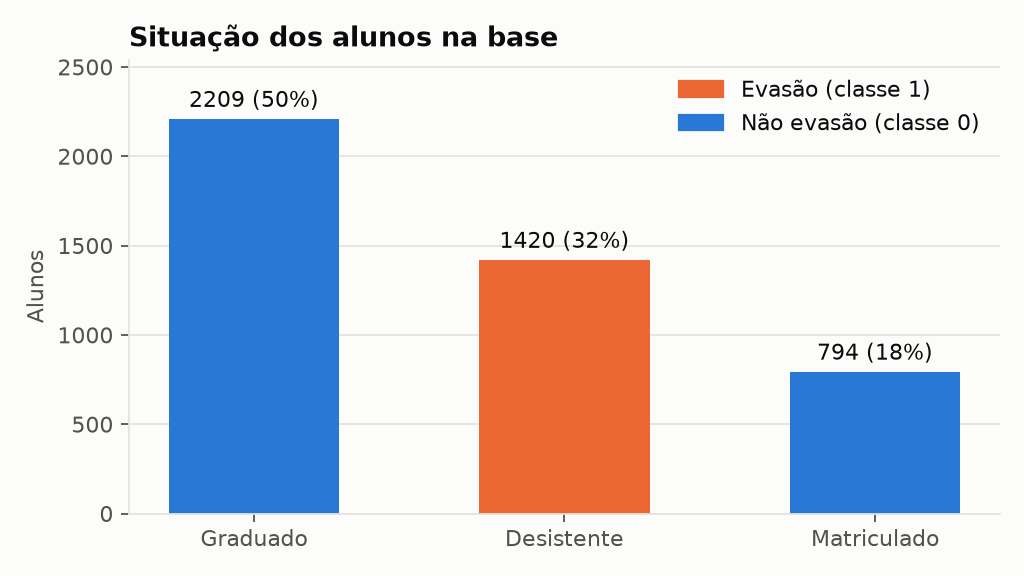

,proporção
Evasao,
Não evasão,0.679
Evasão,0.321


In [10]:
features, target = data.split_features_target(frame)
display(Image(plots.target_distribution(frame[schema.TARGET], schema.DROPOUT_LABEL, schema.FIGURES_DIR / "target_distribution.png")))
target.value_counts(normalize=True).rename({0: "Não evasão", 1: "Evasão"}).to_frame("proporção")

A evasão é 32% da base. O desbalanceamento é moderado, e por isso:

- a acurácia sozinha engana (prever "não evasão" para todo mundo já acerta 68%), então a análise usa também recall, precisão, F1 e ROC AUC;
- a separação e a validação cruzada são estratificadas;
- os modelos usam `class_weight="balanced"`, que dá mais peso aos erros na classe de evasão.

## 4. Exploração rápida

Antes de modelar, vale ver quais variáveis separam as classes.

In [11]:
rates = []
for column in [*schema.BINARY_COLUMNS, "Genero"]:
    for value, group in target.groupby(frame[column]):
        rates.append({"variável": column, "valor": value, "alunos": len(group), "taxa de evasão": group.mean()})
pd.DataFrame(rates)

,variável,valor,alunos,taxa de evasão
0,NecessidadesEspeciais,0,4372,0.321
1,NecessidadesEspeciais,1,51,0.333
2,Devedor,0,3920,0.283
3,Devedor,1,503,0.620
4,MensalidadesEmDia,0,528,0.866
5,MensalidadesEmDia,1,3895,0.247
6,Bolsista,0,3324,0.387
7,Bolsista,1,1099,0.122
8,Genero,Feminino,2868,0.251
9,Genero,Masculino,1555,0.450


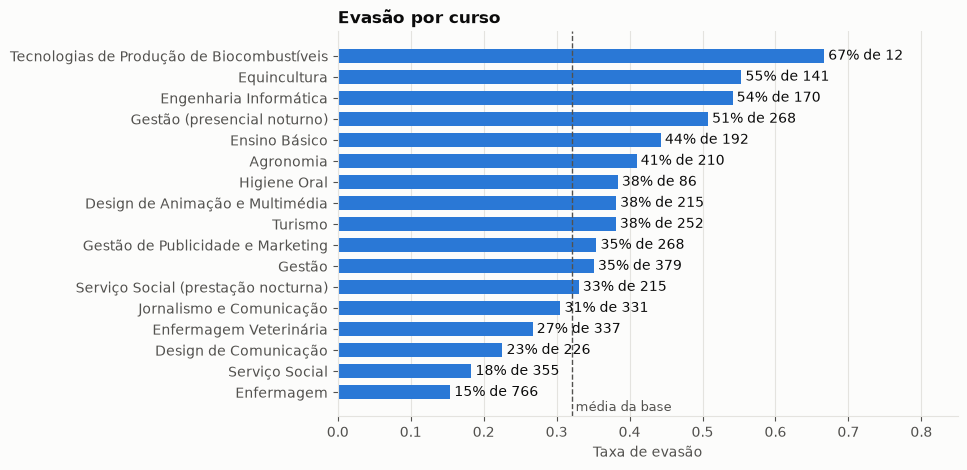

In [12]:
by_course = target.groupby(frame["Curso"]).agg(["mean", "size"]).sort_values("mean")
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(by_course.index, by_course["mean"], color=plots.TRAIN_COLOR, height=0.65)
ax.bar_label(bars, labels=[f"{rate:.0%} de {size}" for rate, size in zip(by_course["mean"], by_course["size"])], padding=3)
ax.axvline(target.mean(), color=plots.TEXT_SECONDARY, linestyle="--", linewidth=1)
ax.text(target.mean() + 0.005, -0.9, "média da base", color=plots.TEXT_SECONDARY, fontsize=9)
ax.set_xlim(0, 0.85)
ax.set_xlabel("Taxa de evasão")
ax.set_title("Evasão por curso")
ax.grid(axis="y", visible=False)
plt.show()

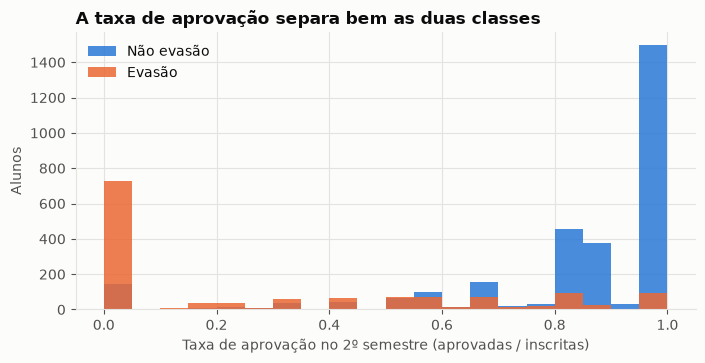

In [13]:
derived = AcademicFeatures().fit_transform(features)
fig, ax = plt.subplots(figsize=(8, 3.6))
bins = np.linspace(0, 1, 21)
ax.hist(derived.loc[target == 0, "TaxaAprovacao2Semestre"], bins=bins, color=plots.TRAIN_COLOR, alpha=0.85, label="Não evasão")
ax.hist(derived.loc[target == 1, "TaxaAprovacao2Semestre"], bins=bins, color=plots.VALIDATION_COLOR, alpha=0.85, label="Evasão")
ax.set_xlabel("Taxa de aprovação no 2º semestre (aprovadas / inscritas)")
ax.set_ylabel("Alunos")
ax.set_title("A taxa de aprovação separa bem as duas classes")
ax.legend()
plt.show()

O que aparece:

- **Mensalidades em dia** é o sinal isolado mais forte: 87% dos alunos com mensalidade atrasada evadem, contra 25% dos demais.
- **Devedores** evadem mais (62% contra 28%) e **bolsistas** evadem menos (12% contra 39%).
- A evasão varia muito por **curso**, de 15% em Enfermagem a mais de 50% em Engenharia Informática e Equincultura.
- No **desempenho**, quem evade aprovou em média 29% das unidades em que se inscreveu no 2º semestre; quem não evade, 83%.

## 5. Feature engineering

O tratamento fica todo dentro de um `Pipeline` do scikit-learn. Assim, cada fold da validação cruzada ajusta a imputação, a padronização e o encoding só com os dados de treino daquele fold, sem vazamento.

### 5.1 Variáveis derivadas

Os contadores brutos dependem do tamanho da grade de cada curso: 5 aprovações significam coisas diferentes para quem se inscreveu em 5 e para quem se inscreveu em 8 unidades. O transformador `AcademicFeatures` cria:

| Variável | Cálculo |
|---|---|
| `TaxaAprovacao{1,2}Semestre` | aprovadas / inscritas (0 quando não há inscrição) |
| `AvaliacoesPorUnidade{1,2}Semestre` | avaliações / inscritas |
| `VariacaoNotaEntreSemestres` | nota do 2º semestre menos a do 1º |
| `VariacaoAprovadasEntreSemestres` | aprovadas no 2º semestre menos as do 1º |
| `SemUnidadesInscritas` | 1 quando o aluno não tem inscrição em nenhum dos dois semestres |

O último indicador existe porque 180 alunos têm todos os contadores zerados. Para eles o zero significa "sem registro", e não "reprovou em tudo".

In [14]:
derived[schema.DERIVED_COLUMNS].describe().T

,count,mean,std,min,25%,50%,75%,max
TaxaAprovacao1Semestre,4423.000,0.698,0.365,0.000,0.500,0.833,1.000,1.000
TaxaAprovacao2Semestre,4423.000,0.661,0.383,0.000,0.400,0.833,1.000,1.000
AvaliacoesPorUnidade1Semestre,4423.000,1.290,0.567,0.000,1.000,1.200,1.600,3.500
AvaliacoesPorUnidade2Semestre,4423.000,1.261,0.579,0.000,1.000,1.167,1.600,3.833
VariacaoNotaEntreSemestres,4423.000,-0.411,2.891,-16.143,-0.600,0.000,0.452,16.000
VariacaoAprovadasEntreSemestres,4423.000,-0.271,1.341,-9.000,-1.000,0.000,0.000,6.000
SemUnidadesInscritas,4423.000,0.041,0.198,0.000,0.000,0.000,0.000,1.000


### 5.2 Numéricas, binárias e categóricas

- **Numéricas** (originais e derivadas): imputação pela mediana e padronização (`StandardScaler`). A base não tem nulos, mas o app aceita planilhas novas e a imputação evita que uma célula vazia derrube a previsão. A padronização é necessária para a regressão logística com regularização e é neutra para os modelos de árvore.
- **Binárias**: seguem como 0/1.
- **Categóricas**: `OneHotEncoder`. Categorias com menos de 20 alunos no treino são agrupadas em uma única coluna de "raras" (`min_frequency=20`), e categorias nunca vistas caem nesse mesmo grupo na previsão. Sem isso, as 12 nacionalidades com um ou dois alunos virariam colunas quase vazias, que só servem para o modelo decorar.
- **`International`** é descartada: ela é igual a "nacionalidade diferente de Português" em todas as linhas, então repete o que o encoding de `Nacionalidade` já informa.

In [15]:
transformed = build_pipeline("passthrough")[:-1].fit_transform(features)
names = build_pipeline("passthrough")[:-1].fit(features).named_steps["preprocessor"].get_feature_names_out()
print(f"{features.shape[1]} colunas de entrada -> {transformed.shape[1]} colunas depois do tratamento")
[name for name in names if "infrequent" in name]

27 colunas de entrada -> 63 colunas depois do tratamento


['EstadoCivil_infrequent_sklearn',
 'Curso_infrequent_sklearn',
 'QualificacaoAnterior_infrequent_sklearn',
 'Nacionalidade_infrequent_sklearn']

## 6. Separação em treino e teste

80% dos alunos vão para o treino e 20% para o teste, com estratificação pelo alvo. O conjunto de teste fica guardado: ele só é usado uma vez, no fim, para medir o modelo escolhido. Toda comparação entre modelos e todo ajuste de hiperparâmetro acontecem dentro do treino, por validação cruzada.

In [16]:
x_train, x_test, y_train, y_test = train.split(features, target)
pd.DataFrame(
    {"alunos": [len(x_train), len(x_test)], "taxa de evasão": [y_train.mean(), y_test.mean()]},
    index=["treino", "teste"],
)

,alunos,taxa de evasão
treino,3538,0.321
teste,885,0.321


## 7. Treino com validação cruzada

A validação cruzada é estratificada em 5 folds (`StratifiedKFold`). Para cada candidato, um `GridSearchCV` testa a grade de hiperparâmetros e guarda as métricas **de treino e de validação** de cada fold. Comparar as duas é o que permite falar de overfitting e underfitting.

Os candidatos:

| Candidato | Papel |
|---|---|
| Árvore rasa (profundidade 1) | referência de modelo simples demais |
| Árvore sem limite de profundidade | referência de modelo que decora o treino |
| Regressão logística | modelo linear com regularização (`C` ajustado) |
| Random forest | conjunto de árvores (`max_depth` e `min_samples_leaf` ajustados) |
| Gradient boosting | árvores em sequência (`learning_rate`, `max_iter` e `max_depth` ajustados) |

In [17]:
searches = {candidate.key: train.search(candidate, x_train, y_train) for candidate in candidates()}
results = pd.DataFrame([train.summarize(candidate, searches[candidate.key]) for candidate in candidates()])
results[["label", "params", "train_roc_auc", "validation_roc_auc", "validation_roc_auc_std", "gap", "train_f1", "validation_f1", "validation_recall", "validation_precision", "validation_accuracy"]]

,label,params,train_roc_auc,validation_roc_auc,validation_roc_auc_std,gap,train_f1,validation_f1,validation_recall,validation_precision,validation_accuracy
0,Árvore rasa (profundidade 1),{},0.812,0.810,0.017,0.002,0.733,0.731,0.826,0.656,0.805
1,Árvore sem limite de profundidade,{},1.000,0.773,0.010,0.227,1.000,0.691,0.701,0.683,0.799
2,Regressão logística,{'C': 0.1},0.920,0.912,0.012,0.008,0.794,0.779,0.799,0.761,0.854
3,Random forest,"{'max_depth': None, 'min_samples_leaf': 5}",0.974,0.913,0.009,0.061,0.866,0.779,0.801,0.759,0.854
4,Gradient boosting,"{'learning_rate': 0.1, 'max_depth': 3, 'max_it...",0.952,0.915,0.009,0.037,0.835,0.789,0.801,0.778,0.862


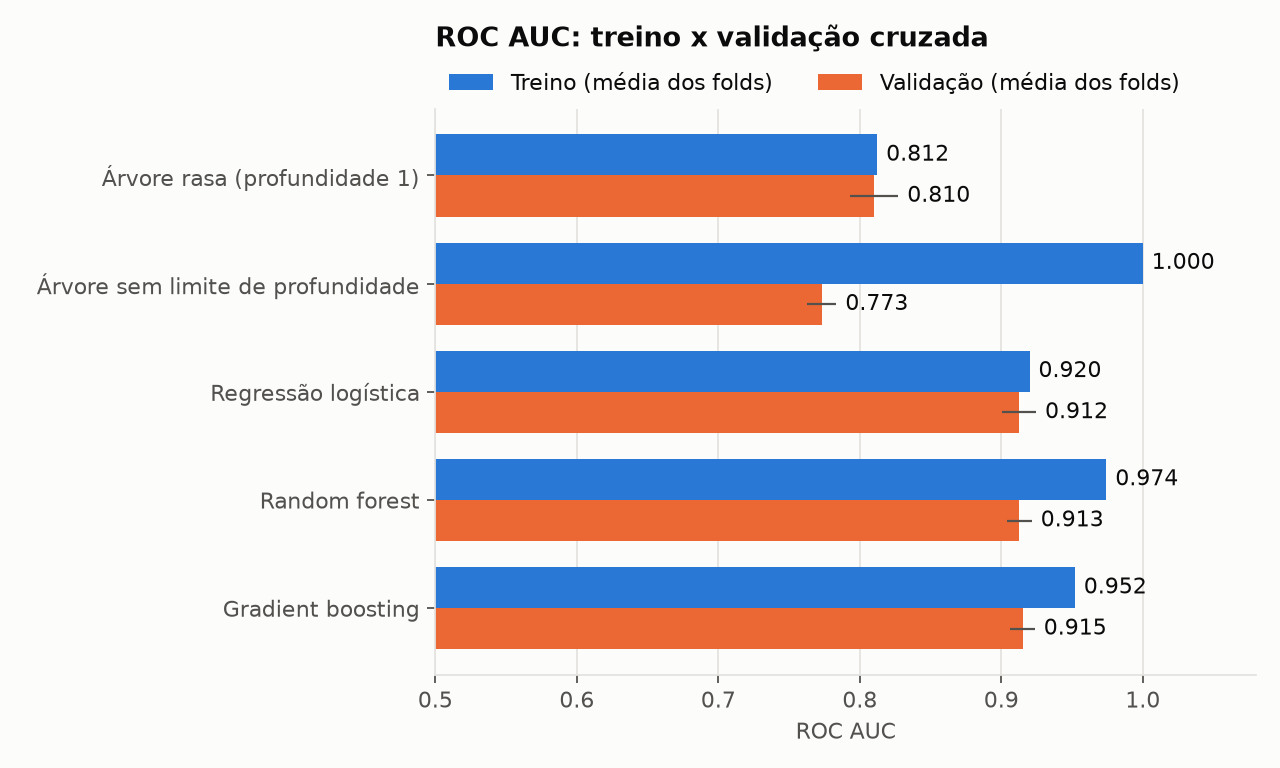

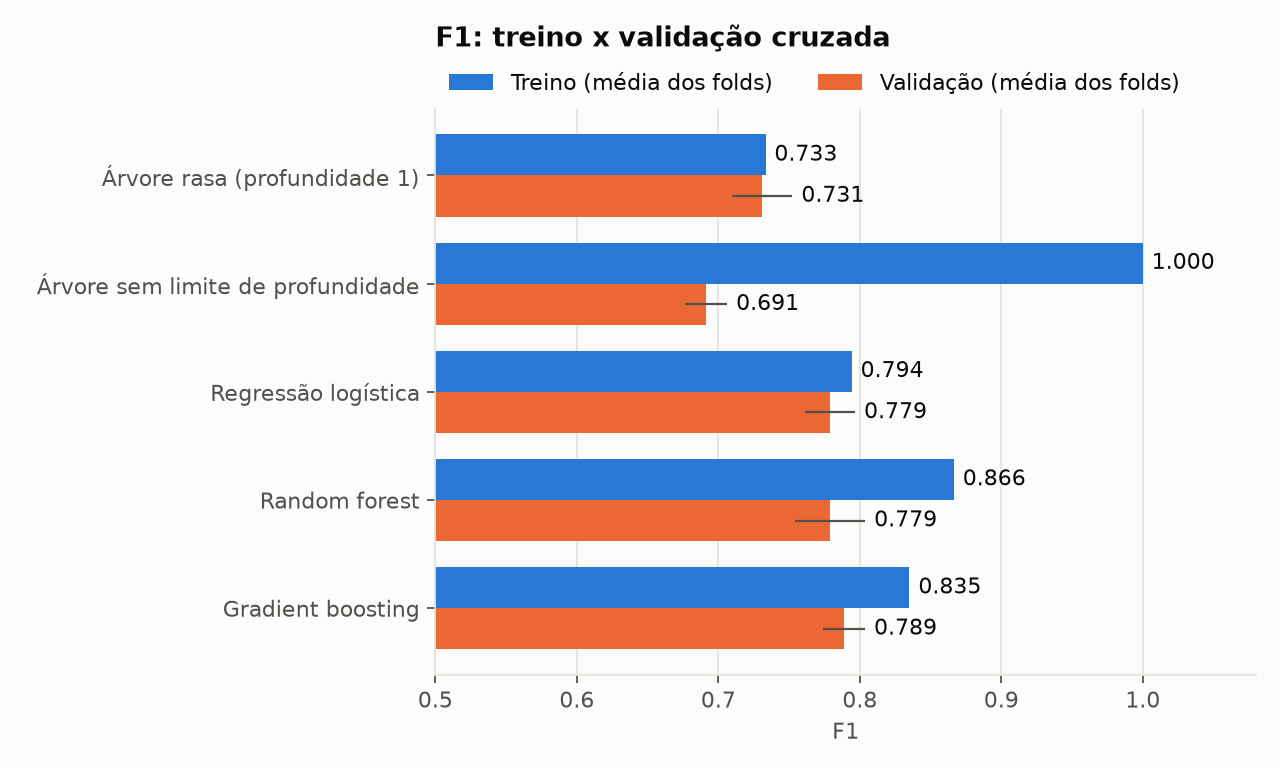

In [18]:
display(Image(plots.train_vs_validation(results, "roc_auc", "ROC AUC", schema.FIGURES_DIR / "cv_roc_auc.png")))
display(Image(plots.train_vs_validation(results, "f1", "F1", schema.FIGURES_DIR / "cv_f1.png")))

## 8. Overfitting e underfitting

A leitura é sempre a mesma: comparar o desempenho no treino com o desempenho na validação.

- **Underfitting**: treino e validação baixos e parecidos. O modelo não tem capacidade para capturar o padrão.
- **Overfitting**: treino muito acima da validação. O modelo aprendeu particularidades do treino que não se repetem em dados novos.
- **Ajuste adequado**: validação alta e próxima do treino.

### 8.1 Nos candidatos

- A **árvore rasa** tem AUC de 0,812 no treino e 0,810 na validação. A diferença é quase zero, mas os dois valores ficam 0,10 abaixo dos melhores modelos: é **underfitting**. Uma única pergunta sobre o aluno não basta.
- A **árvore sem limite** chega a AUC 1,000 no treino e cai para 0,773 na validação, pior que a árvore rasa. É **overfitting** claro: ela separa perfeitamente os alunos que viu e erra mais nos que não viu.
- A **random forest** (0,974 no treino, 0,913 na validação) e o **gradient boosting** (0,952 e 0,915) generalizam bem, mas ainda carregam uma diferença de 0,04 a 0,06 entre treino e validação: há algum overfitting, que não chega a prejudicar a validação.
- A **regressão logística** tem 0,920 no treino e 0,912 na validação, diferença de 0,008. É o melhor equilíbrio: validação no mesmo patamar dos conjuntos de árvores, com quase nenhuma distância para o treino.

### 8.2 Curva de validação

Para ver a transição completa, a mesma árvore de decisão é treinada com profundidade máxima de 1 a 20.

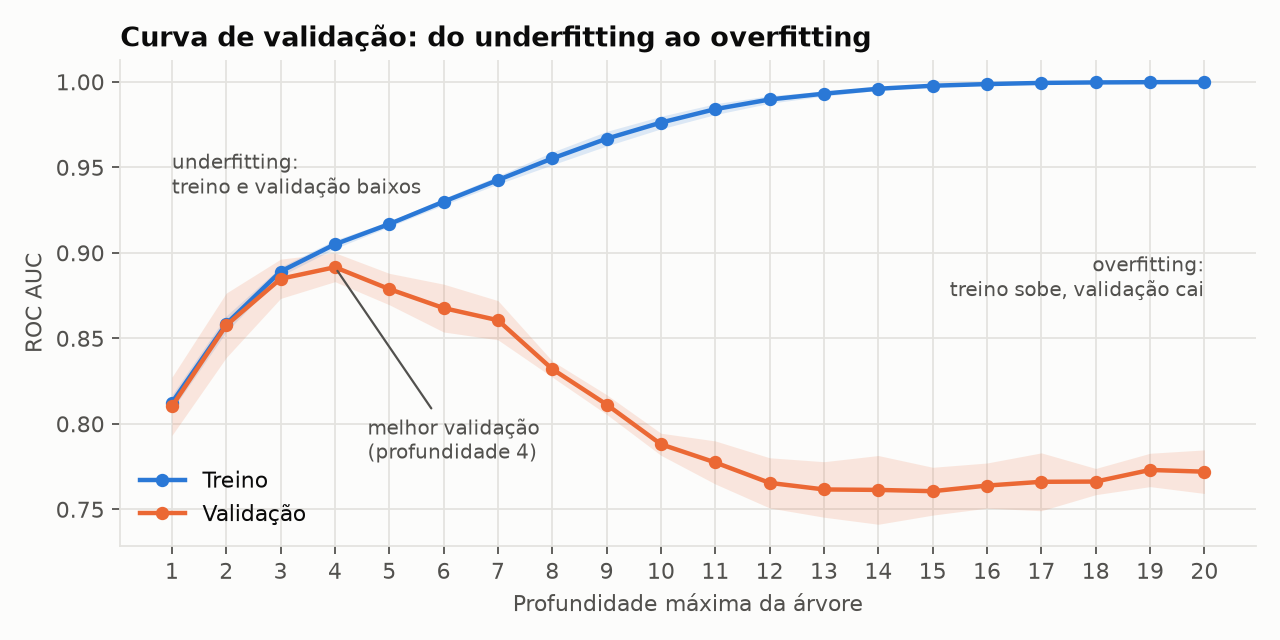

In [19]:
depth_train, depth_validation = train.tree_depth_curve(x_train, y_train)
display(Image(plots.validation_curve_figure(train.TREE_DEPTHS, depth_train, depth_validation, "ROC AUC", schema.FIGURES_DIR / "validation_curve.png")))

Até a profundidade 4, treino e validação sobem juntos: o modelo está saindo do underfitting. A partir daí o treino continua subindo até 1,0 e a validação cai de 0,89 para 0,77. Cada nível a mais de profundidade passa a aprender ruído.

### 8.3 Seleção do modelo

Regressão logística, random forest e gradient boosting ficam entre 0,912 e 0,915 de AUC na validação, com desvio de 0,01 entre os folds. Essa diferença está dentro do ruído. A regra de seleção usada é a de um erro padrão: entre os candidatos que empatam com o melhor (média de validação a até um erro padrão do melhor), fica o que tem a **menor diferença entre treino e validação**.

In [20]:
selected_key = train.select(results)
selected = results.set_index("key").loc[selected_key]
model = searches[selected_key].best_estimator_
selected[["label", "params", "train_roc_auc", "validation_roc_auc", "gap"]].to_frame("modelo escolhido")

,modelo escolhido
label,Regressão logística
params,{'C': 0.1}
train_roc_auc,0.920
validation_roc_auc,0.912
gap,0.008


### 8.4 Curva de aprendizado do modelo escolhido

A curva de aprendizado mostra o que acontece com treino e validação conforme o modelo recebe mais alunos.

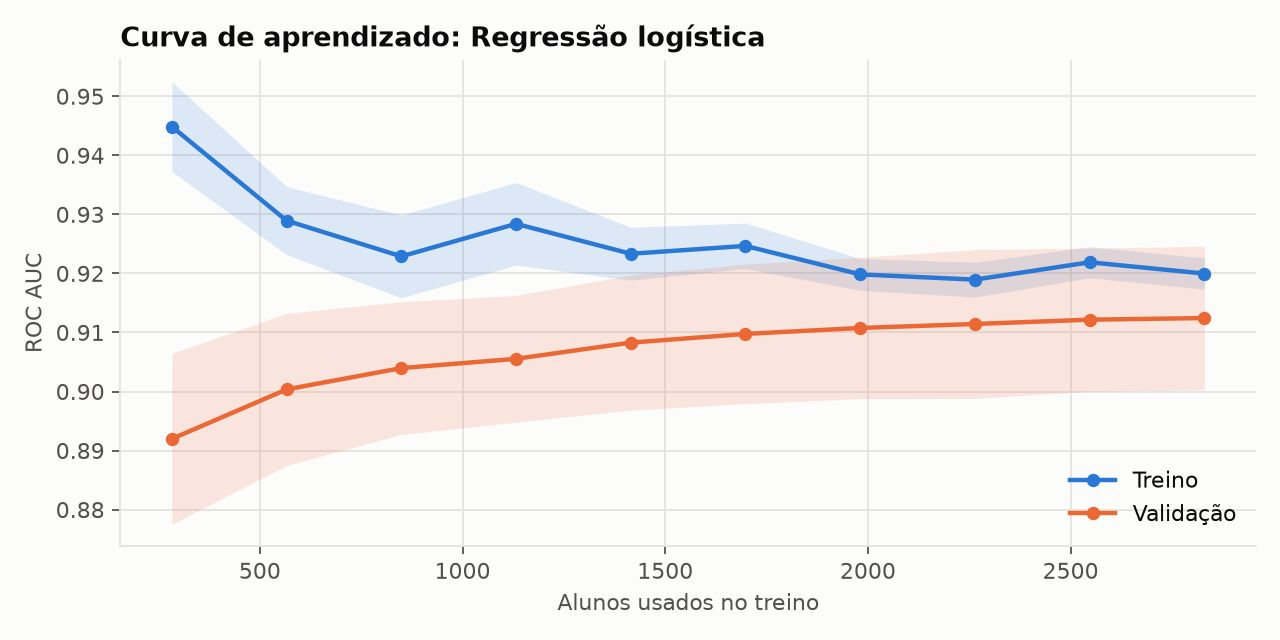

In [21]:
sizes, curve_train, curve_validation = learning_curve(
    model, x_train, y_train, train_sizes=np.linspace(0.1, 1.0, 10), scoring=train.SELECTION_METRIC, cv=train.cross_validator(), n_jobs=-1
)
display(Image(plots.learning_curve_figure(sizes, curve_train, curve_validation, "ROC AUC", selected["label"], schema.FIGURES_DIR / "learning_curve.png")))

Com poucos alunos, o treino fica em 0,945 e a validação em 0,892. Conforme o treino cresce, as duas curvas convergem para perto de 0,92 e 0,91. Curvas que se encontram num patamar alto indicam que não há overfitting relevante. A validação quase não sobe nos últimos pontos, então mais dados do mesmo tipo trariam pouco ganho: para melhorar seria preciso informação nova sobre os alunos, e não mais linhas.

## 9. Avaliação final no conjunto de teste

O modelo escolhido foi treinado em todo o conjunto de treino. Agora ele é medido, uma única vez, nos 885 alunos de teste.

In [22]:
test_metrics = train.evaluate(model, x_test, y_test)
comparison = pd.DataFrame(
    {
        "treino (CV)": [selected[f"train_{metric}"] for metric in train.SCORING],
        "validação (CV)": [selected[f"validation_{metric}"] for metric in train.SCORING],
        "teste": [test_metrics[metric] for metric in train.SCORING],
    },
    index=train.SCORING,
)
comparison

,treino (CV),validação (CV),teste
accuracy,0.864,0.854,0.881
precision,0.774,0.761,0.797
recall,0.815,0.799,0.845
f1,0.794,0.779,0.821
roc_auc,0.920,0.912,0.936


In [23]:
probability = model.predict_proba(x_test)[:, 1]
predicted = (probability >= train.DECISION_THRESHOLD).astype(int)
print(classification_report(y_test, predicted, target_names=["Não evasão", "Evasão"], digits=3))

              precision    recall  f1-score   support

  Não evasão      0.925     0.899     0.911       601
      Evasão      0.797     0.845     0.821       284

    accuracy                          0.881       885
   macro avg      0.861     0.872     0.866       885
weighted avg      0.884     0.881     0.882       885



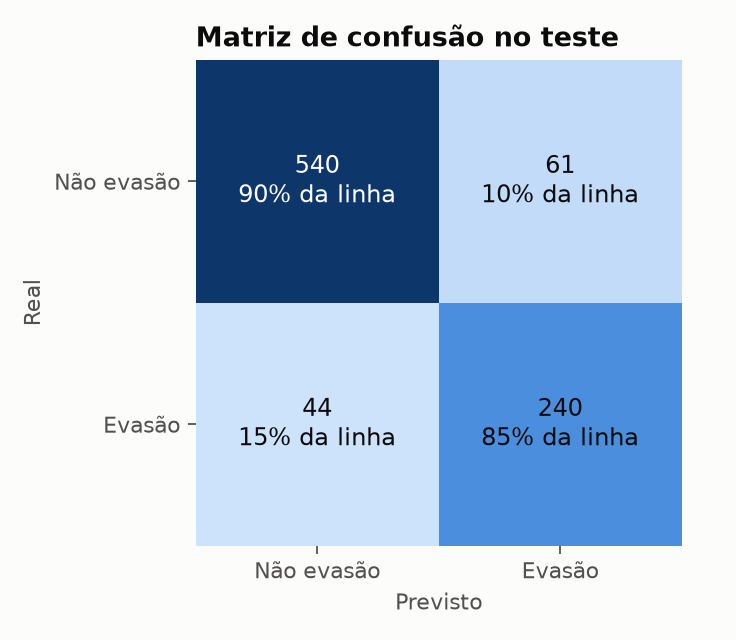

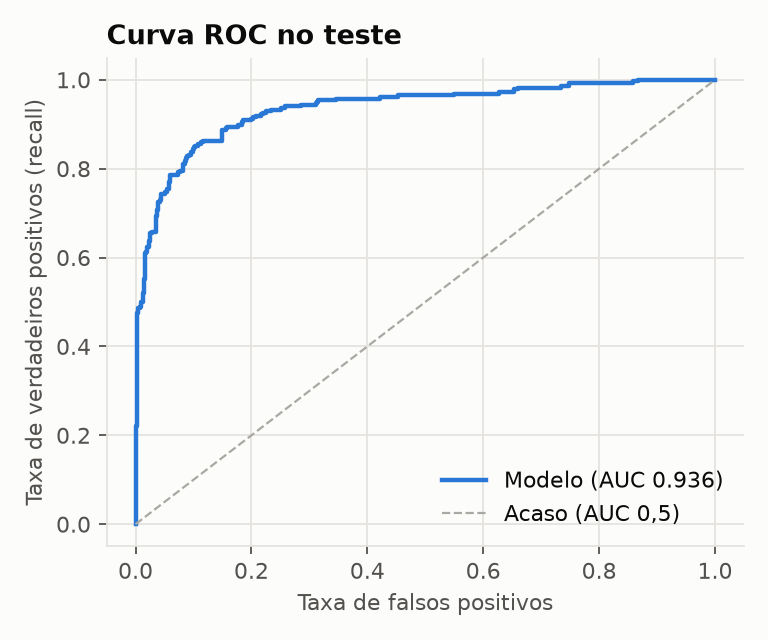

In [24]:
false_positive_rate, true_positive_rate, _ = roc_curve(y_test, probability)
display(Image(plots.confusion_matrix_figure(np.array(test_metrics["confusion_matrix"]), schema.FIGURES_DIR / "confusion_matrix.png")))
display(Image(plots.roc_curve_figure(false_positive_rate, true_positive_rate, test_metrics["roc_auc"], schema.FIGURES_DIR / "roc_curve.png")))

No teste o modelo tem AUC de 0,936, recall de 0,845 e precisão de 0,797 para evasão. As métricas de teste ficaram um pouco **acima** das de validação. Isso não é sinal de problema: o teste é uma amostra única de 885 alunos e a diferença (0,02 de AUC) é da ordem de duas vezes o desvio entre os folds. O que importa é que o desempenho em dados nunca vistos não caiu em relação ao treino, o que confirma a leitura da validação cruzada: **não houve overfitting nem underfitting no modelo final**.

Na prática: de 284 alunos que evadiram no teste, o modelo sinalizou 240 e deixou passar 44. De 601 que não evadiram, 61 foram sinalizados à toa.

## 10. O que pesa na previsão

A importância por permutação embaralha uma coluna de entrada por vez e mede quanto o AUC cai no teste.

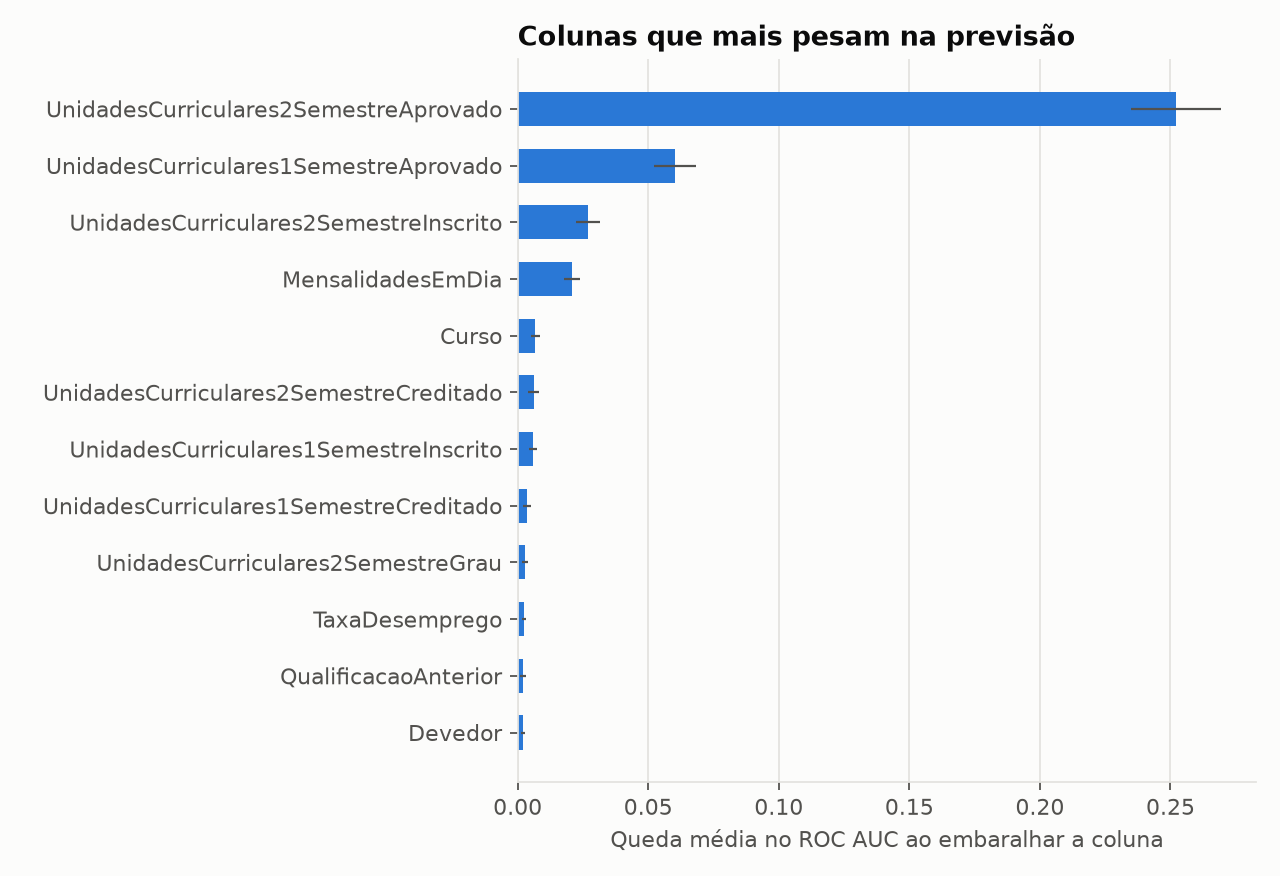

In [25]:
importances = train.raw_importances(model, x_test, y_test)
display(Image(plots.feature_importance_figure(importances, schema.FIGURES_DIR / "feature_importance.png")))

In [26]:
coefficients = pd.Series(
    model.named_steps["classifier"].coef_[0], index=model.named_steps["preprocessor"].get_feature_names_out()
)
coefficients.sort_values(key=np.abs, ascending=False).head(12).to_frame("coeficiente (log-odds)")

,coeficiente (log-odds)
MensalidadesEmDia,-1.705
TaxaAprovacao2Semestre,-0.736
UnidadesCurriculares2SemestreAprovado,-0.734
UnidadesCurriculares1SemestreAprovado,-0.690
Curso_Ensino Básico,0.599
Curso_Equincultura,0.461
Curso_Serviço Social,-0.451
Devedor,0.437
QualificacaoAnterior_Curso de Especialização Tecnológica,-0.425
SemUnidadesInscritas,-0.410


O desempenho no 2º semestre domina: as unidades aprovadas e inscritas alimentam também a taxa de aprovação, que é uma das variáveis derivadas com maior coeficiente. Em seguida vem a situação financeira (mensalidades em dia, devedor, bolsista) e depois o curso.

## 11. Conclusões

1. **Dados**: a base precisou de um reparo antes de qualquer modelagem. As notas semestrais estavam sem o separador decimal em cerca de 40% das linhas, e o alvo de três classes foi convertido em binário (Desistente contra o resto).
2. **Feature engineering**: taxas de aprovação e variações entre semestres tornam os contadores comparáveis entre cursos; numéricas padronizadas; categóricas em one-hot com as categorias raras agrupadas. Tudo dentro do `Pipeline`, sem vazamento entre folds.
3. **Validação cruzada**: 5 folds estratificados dentro do treino, comparando cinco candidatos pelas métricas de treino e de validação.
4. **Underfitting e overfitting**: a árvore rasa mostra underfitting (AUC 0,81 em treino e validação) e a árvore sem limite mostra overfitting (1,00 no treino, 0,77 na validação). A regressão logística escolhida não apresenta nenhum dos dois: 0,920 no treino, 0,912 na validação e 0,936 no teste.
5. **Resultado**: o modelo identifica 85% dos alunos que evadem, com 80% de precisão.
6. **Limites**: as variáveis mais fortes só existem depois do 2º semestre, então o modelo não serve para prever evasão na matrícula. O score sai de um modelo com pesos balanceados e ordena bem os alunos por risco, mas não é uma probabilidade calibrada.